**Chapter 9 – Introduction to Artificial Neural Networks**

_This notebook contains all the sample code and solutions to the exercises in chapter 9._

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/PGupta-Git/handson-mlp/blob/polars_integration/09_artificial_neural_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
  <td>
    <a target="_blank" href="https://kaggle.com/kernels/welcome?src=https://github.com/PGupta-Git/handson-mlp/blob/polars_integration/09_artificial_neural_networks.ipynb"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" /></a>
  </td>
</table>

# Setup

This project requires Python 3.10 or above:

In [1]:
import sys

assert sys.version_info >= (3, 11)

It also requires Scikit-Learn ≥ 1.6.1:

In [2]:
from packaging.version import Version
import sklearn

assert Version(sklearn.__version__) >= Version("1.9.1")

As we did in previous chapters, let's define the default font sizes to make the figures prettier:

In [3]:
import matplotlib.pyplot as plt

plt.rc("font", size=14)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=14)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)

# From Biological to Artificial Neurons
## The Perceptron

In [4]:
import numpy as np
import polars as pl
from sklearn.datasets import load_iris
from sklearn.linear_model import Perceptron

iris = load_iris()
iris_data = pl.DataFrame(iris.data, schema=iris.feature_names)
X = iris_data.select("petal length (cm)", "petal width (cm)").to_numpy()
y = iris.target == 0  # Iris setosa

per_clf = Perceptron(random_state=42)
per_clf.fit(X, y)

X_new = [[2, 0.5], [3, 1]]
y_pred = per_clf.predict(X_new)  # predicts True and False for these 2 flowers

In [5]:
y_pred

array([ True, False])

The `Perceptron` is equivalent to a `SGDClassifier` with `loss="perceptron"`, no regularization, and a constant learning rate equal to 1:

In [6]:
# extra code – shows how to build and train a Perceptron

from sklearn.linear_model import SGDClassifier

sgd_clf = SGDClassifier(
    loss="perceptron", penalty=None, learning_rate="constant", eta0=1, random_state=42
)
sgd_clf.fit(X, y)
assert (sgd_clf.coef_ == per_clf.coef_).all()
assert (sgd_clf.intercept_ == per_clf.intercept_).all()

When the Perceptron finds a decision boundary that properly separates the classes, it stops learning. This means that the decision boundary is often quite close to one class:

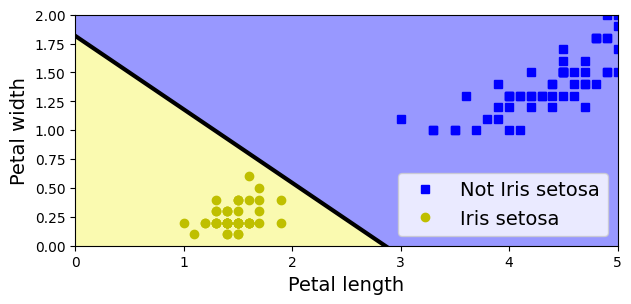

In [7]:
# extra code – plots the decision boundary of a Perceptron on the iris dataset

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

a = -per_clf.coef_[0, 0] / per_clf.coef_[0, 1]
b = -per_clf.intercept_ / per_clf.coef_[0, 1]
axes = [0, 5, 0, 2]
x0, x1 = np.meshgrid(
    np.linspace(axes[0], axes[1], 500).reshape(-1, 1),
    np.linspace(axes[2], axes[3], 200).reshape(-1, 1),
)
X_new = np.c_[x0.ravel(), x1.ravel()]
y_predict = per_clf.predict(X_new)
zz = y_predict.reshape(x0.shape)
custom_cmap = ListedColormap(["#9898ff", "#fafab0"])

plt.figure(figsize=(7, 3))
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Not Iris setosa")
plt.plot(X[y == 1, 0], X[y == 1, 1], "yo", label="Iris setosa")
plt.plot([axes[0], axes[1]], [a * axes[0] + b, a * axes[1] + b], "k-", linewidth=3)
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="lower right")
plt.axis(axes)
plt.show()

**Activation functions**

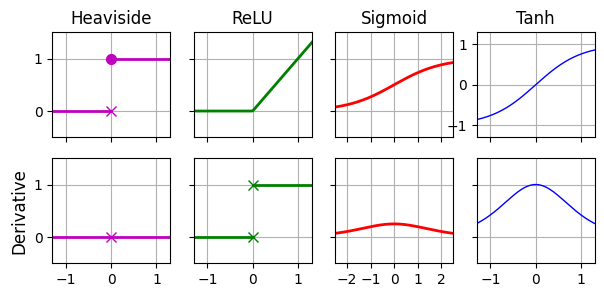

In [8]:
# extra code – this cell generates Figure 9–8

from scipy.special import expit as sigmoid


def relu(z):
    return np.maximum(0, z)


def derivative(f, z, eps=0.000001):
    return (f(z + eps) - f(z - eps)) / (2 * eps)


max_z = 2.5
z = np.linspace(-max_z, max_z, 200)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(7, 3))

axes[0, 0].plot([-max_z, 0], [0, 0], "m-", linewidth=2)
axes[0, 0].plot(0, 0, "mx", markersize=7)
axes[0, 0].plot(0, 1, "mo", markersize=7)
axes[0, 0].plot([0, max_z], [1, 1], "m-", linewidth=2)
axes[0, 0].set_title("Heaviside", fontsize=12)
axes[1, 0].plot(z, derivative(np.sign, z), "m-", linewidth=2)
axes[1, 0].plot(0, 0, "mx", markersize=7)
axes[1, 0].set_ylabel("Derivative", fontsize=12)

axes[0, 1].plot(z, relu(z), "g-", linewidth=2)
axes[0, 1].set_title("ReLU", fontsize=12)
axes[1, 1].plot([-max_z, 0], [0, 0], "g-", linewidth=2)
axes[1, 1].plot([0, max_z], [1, 1], "g-", linewidth=2)
axes[1, 1].plot(0, 0, "gx", markersize=7)
axes[1, 1].plot(0, 1, "gx", markersize=7)

axes[0, 2].plot(z, sigmoid(z), "r-", linewidth=2)
axes[0, 2].set_title("Sigmoid", fontsize=12)
axes[1, 2].plot(z, derivative(sigmoid, z), "r-", linewidth=2)

axes[0, 3].plot(z, np.tanh(z), "b-", linewidth=1)
axes[0, 3].set_title("Tanh", fontsize=12)
axes[1, 3].plot(z, derivative(np.tanh, z), "b-", linewidth=1)

for row in range(2):
    for col in range(4):
        axes[row, col].grid(True)
        if row == 0:
            axes[row, col].set_xticklabels([])
        if col == 2:
            axes[row, col].set_xlim(-max_z, max_z)
            axes[row, col].set_xticks([-2, -1, 0, 1, 2])
        else:
            axes[row, col].set_xlim(-1.3, 1.3)
            axes[row, col].set_xticks([-1, 0, 1])
        if col != 0 and ((row, col) != (0, 3)):
            axes[row, col].set_yticklabels([])
        if (row, col) == (0, 3):
            axes[row, col].set_ylim(-1.3, 1.3)
            axes[row, col].set_yticks([-1, 0, 1])
        else:
            axes[row, col].set_ylim(-0.5, 1.5)
            axes[row, col].set_yticks([0, 1])

plt.show()

# Building and Training MLPs with Scikit-Learn
## Regression MLPs

In [9]:
from sklearn.datasets import fetch_california_housing
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [10]:
housing = fetch_california_housing()
X_train, X_test, y_train, y_test = train_test_split(
    housing.data, housing.target, random_state=42
)

In [11]:
mlp_reg = MLPRegressor(
    hidden_layer_sizes=[50, 50, 50], early_stopping=True, verbose=True, random_state=42
)

In [12]:
pipeline = make_pipeline(StandardScaler(), mlp_reg)
pipeline.fit(X_train, y_train)

Iteration 1, loss = 0.85190332
Validation score: 0.534299
Iteration 2, loss = 0.28288639
Validation score: 0.651094
Iteration 3, loss = 0.22884372
Validation score: 0.699782
Iteration 4, loss = 0.20746145
Validation score: 0.720468
Iteration 5, loss = 0.19649383
Validation score: 0.724839
Iteration 6, loss = 0.18928708
Validation score: 0.740084
Iteration 7, loss = 0.18132029
Validation score: 0.747406
Iteration 8, loss = 0.17556450
Validation score: 0.753945


Iteration 9, loss = 0.17190651
Validation score: 0.760500
Iteration 10, loss = 0.16687650
Validation score: 0.759213
Iteration 11, loss = 0.16329479
Validation score: 0.761907
Iteration 12, loss = 0.16054473
Validation score: 0.768950
Iteration 13, loss = 0.15690181
Validation score: 0.762699
Iteration 14, loss = 0.15630644
Validation score: 0.766003
Iteration 15, loss = 0.15712517
Validation score: 0.778464
Iteration 16, loss = 0.15155981
Validation score: 0.774237


Iteration 17, loss = 0.14957641
Validation score: 0.778361
Iteration 18, loss = 0.14728922
Validation score: 0.780102
Iteration 19, loss = 0.14536327
Validation score: 0.780951
Iteration 20, loss = 0.14563414
Validation score: 0.776231
Iteration 21, loss = 0.14425158
Validation score: 0.783802
Iteration 22, loss = 0.14417076
Validation score: 0.779485
Iteration 23, loss = 0.14505477
Validation score: 0.781090
Iteration 24, loss = 0.14213671
Validation score: 0.778097


Iteration 25, loss = 0.14193655
Validation score: 0.784260
Iteration 26, loss = 0.14049307
Validation score: 0.784079
Iteration 27, loss = 0.13866098
Validation score: 0.780657
Iteration 28, loss = 0.13808885
Validation score: 0.786546
Iteration 29, loss = 0.13754874
Validation score: 0.788277
Iteration 30, loss = 0.13686441
Validation score: 0.785461
Iteration 31, loss = 0.13801360
Validation score: 0.781712
Iteration 32, loss = 0.13660210
Validation score: 0.786355


Iteration 33, loss = 0.13560290
Validation score: 0.776844
Iteration 34, loss = 0.13509029
Validation score: 0.791536
Iteration 35, loss = 0.13429967
Validation score: 0.788331
Iteration 36, loss = 0.13504045
Validation score: 0.776982
Iteration 37, loss = 0.13304051
Validation score: 0.785589
Iteration 38, loss = 0.13274860
Validation score: 0.787238
Iteration 39, loss = 0.13230347
Validation score: 0.778374
Iteration 40, loss = 0.13260752
Validation score: 0.791206


Iteration 41, loss = 0.13076986
Validation score: 0.786876
Iteration 42, loss = 0.13270492
Validation score: 0.783576
Iteration 43, loss = 0.13024949
Validation score: 0.790473
Iteration 44, loss = 0.13194766
Validation score: 0.791439
Iteration 45, loss = 0.12960481
Validation score: 0.788517
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](8,)","[ 3.88, 28.6 , 5.44,..., 3.11, 35.65,-119.58]"


In [13]:
mlp_reg.best_validation_score_

0.791536125425778

In [14]:
y_pred = pipeline.predict(X_test)
rmse = root_mean_squared_error(y_test, y_pred)

In [15]:
rmse

0.5327699946812925

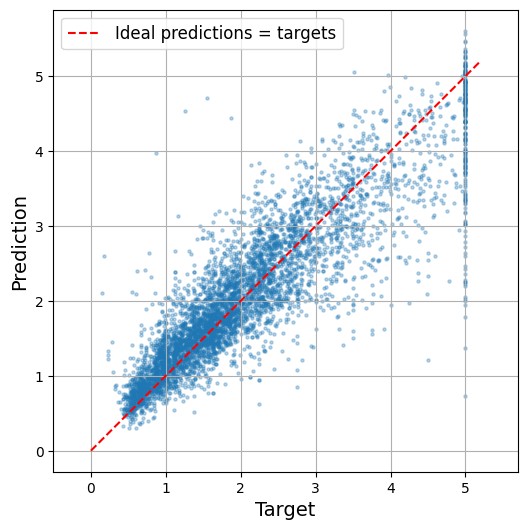

In [16]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=5, alpha=0.3)
plt.plot(
    [0, 5.2], [0, 5.2], color="red", linestyle="--", label="Ideal predictions = targets"
)
plt.axis("equal")
plt.xlabel("Target")
plt.ylabel("Prediction")
plt.legend(fontsize=12)
plt.grid()

plt.show()

## Classification MLPs

In [17]:
from sklearn.datasets import fetch_openml

fashion_mnist = fetch_openml(name="Fashion-MNIST", as_frame=False)
targets = fashion_mnist.target.astype(int)

In [18]:
X_train, y_train = fashion_mnist.data[:60_000], targets[:60_000]
X_test, y_test = fashion_mnist.data[60_000:], targets[60_000:]

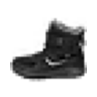

In [19]:
X_sample = X_train[0].reshape(28, 28)  # first image in the training set
plt.figure(figsize=(1, 1))  # extra code – reduce the figure size
plt.imshow(X_sample, cmap="binary")
plt.axis("off")  # extra code – remove the axis
plt.show()

In [20]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

In [21]:
class_names[y_train[0]]

'Ankle boot'

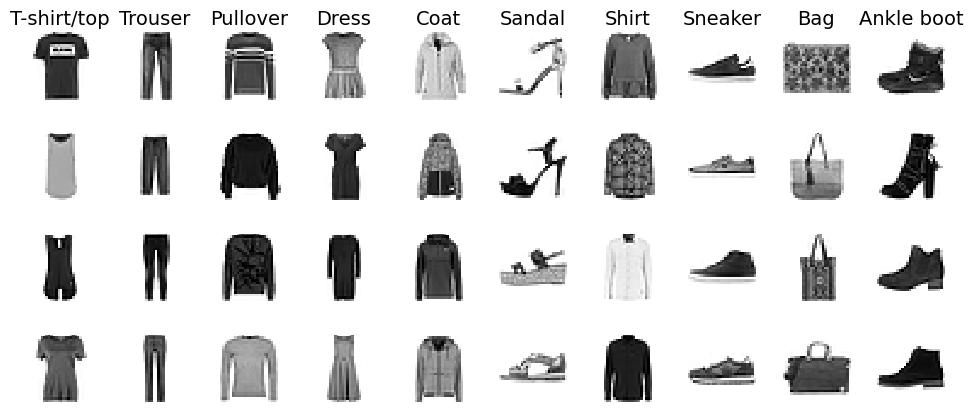

In [22]:
# extra code – this cell generates Figure 9–10
n_rows = 4
plt.figure(figsize=(12, n_rows * 1.2))
for row in range(n_rows):
    for class_index in range(10):
        X_img = X_train[y_train == class_index][row].reshape(28, 28)
        y_img = y_train[y_train == class_index][row]
        plt.subplot(n_rows, 10, 10 * row + class_index + 1)
        plt.imshow(X_img, cmap="binary", interpolation="nearest")
        plt.axis("off")
        if row == 0:
            plt.title(class_names[y_img])
plt.subplots_adjust(wspace=0.2, hspace=0.5)

plt.show()

In [23]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler

mlp_clf = MLPClassifier(
    hidden_layer_sizes=[200, 100], verbose=True, early_stopping=True, random_state=42
)
pipeline = make_pipeline(MinMaxScaler(), mlp_clf)
pipeline.fit(X_train, y_train)
accuracy = pipeline.score(X_test, y_test)

Iteration 1, loss = 0.57483807
Validation score: 0.849333


Iteration 2, loss = 0.39938584
Validation score: 0.856833


Iteration 3, loss = 0.35435272
Validation score: 0.869333


Iteration 4, loss = 0.32570927
Validation score: 0.863833


Iteration 5, loss = 0.30588352
Validation score: 0.874167


Iteration 6, loss = 0.29053832
Validation score: 0.874000


Iteration 7, loss = 0.27455976
Validation score: 0.879333


Iteration 8, loss = 0.26407281
Validation score: 0.878500


Iteration 9, loss = 0.25317835
Validation score: 0.882167


Iteration 10, loss = 0.24414312
Validation score: 0.892833


Iteration 11, loss = 0.23601645
Validation score: 0.890000


Iteration 12, loss = 0.23008384
Validation score: 0.887333


Iteration 13, loss = 0.22123722
Validation score: 0.885167


Iteration 14, loss = 0.21190658
Validation score: 0.879333


Iteration 15, loss = 0.20617121
Validation score: 0.892667


Iteration 16, loss = 0.19935674
Validation score: 0.891667


Iteration 17, loss = 0.19323595
Validation score: 0.891667


Iteration 18, loss = 0.19118498
Validation score: 0.893000


Iteration 19, loss = 0.18045888
Validation score: 0.892167


Iteration 20, loss = 0.17755098
Validation score: 0.890167


Iteration 21, loss = 0.17412956
Validation score: 0.894333


Iteration 22, loss = 0.16773934
Validation score: 0.894500


Iteration 23, loss = 0.16349204
Validation score: 0.893667


Iteration 24, loss = 0.16077870
Validation score: 0.889833


Iteration 25, loss = 0.14934062
Validation score: 0.893333


Iteration 26, loss = 0.14898857
Validation score: 0.888167


Iteration 27, loss = 0.14688411
Validation score: 0.891000


Iteration 28, loss = 0.14079827
Validation score: 0.886667


Iteration 29, loss = 0.14018731
Validation score: 0.887500


Iteration 30, loss = 0.13149282
Validation score: 0.893667


Iteration 31, loss = 0.13008545
Validation score: 0.893500


Iteration 32, loss = 0.12518664
Validation score: 0.892167


Iteration 33, loss = 0.12089552
Validation score: 0.895500


Iteration 34, loss = 0.11773432
Validation score: 0.893167


Iteration 35, loss = 0.11628895
Validation score: 0.890167


Iteration 36, loss = 0.11659955
Validation score: 0.894000


Iteration 37, loss = 0.11052450
Validation score: 0.894833


Iteration 38, loss = 0.10588123
Validation score: 0.890833


Iteration 39, loss = 0.10723341
Validation score: 0.893333


Iteration 40, loss = 0.09899926
Validation score: 0.889000


Iteration 41, loss = 0.09704682
Validation score: 0.890500


Iteration 42, loss = 0.09681605
Validation score: 0.896500


Iteration 43, loss = 0.09534991
Validation score: 0.894000


Iteration 44, loss = 0.08673413
Validation score: 0.894000


Iteration 45, loss = 0.08536987
Validation score: 0.886500


Iteration 46, loss = 0.08287298
Validation score: 0.892167


Iteration 47, loss = 0.08708278
Validation score: 0.895000


Iteration 48, loss = 0.08078388
Validation score: 0.892333


Iteration 49, loss = 0.07876723
Validation score: 0.893000


Iteration 50, loss = 0.07656002
Validation score: 0.894833


Iteration 51, loss = 0.07418611
Validation score: 0.894333


Iteration 52, loss = 0.07863841
Validation score: 0.893333


Iteration 53, loss = 0.06864580
Validation score: 0.891500
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


In [24]:
accuracy

0.8907

In [25]:
mlp_clf.best_validation_score_

0.8965

In [26]:
mlp_clf.score(X_test, y_test)

0.8713

In [27]:
X_new = X_test[:15]  # let's pretend these are 15 new images
mlp_clf.predict(X_new)

array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 8, 3, 4])

In [28]:
y_test[:15]

array([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 7, 3, 4])

In [29]:
y_proba = mlp_clf.predict_proba(X_new)
y_proba[12]

array([0., 0., 0., 0., 0., 0., 0., 0., 1., 0.])

In [30]:
y_proba = mlp_clf.predict_proba(X_test)
(y_proba.max(axis=1) < 0.999).sum()

np.int64(24)

In [31]:
y_proba.max(axis=1)

array([1., 1., 1., ..., 1., 1., 1.], shape=(10000,))

In [32]:
y_proba = mlp_clf.predict_proba(X_test)
sum(y_proba.max(axis=1) < 0.99)

np.int64(16)

# Exercise solutions

## Exercises 1. to 9.

1. Visit the [TensorFlow Playground](https://playground.tensorflow.org/) and play around with it, as described in this exercise.
2. Here is a neural network based on the original artificial neurons that computes _A_ ⊕ _B_ (where ⊕ represents the exclusive OR), using the fact that _A_ ⊕ _B_ = (_A_ ∧ ¬ _B_) ∨ (¬ _A_ ∧ _B_). There are other solutions—for example, using the fact that _A_ ⊕ _B_ = (_A_ ∨ _B_) ∧ ¬(_A_ ∧ _B_), or the fact that _A_ ⊕ _B_ = (_A_ ∨ _B_) ∧ (¬ _A_ ∨ ¬ _B_), and so on.<br /><img width="70%" src="https://github.com/ageron/handson-ml3/blob/main/images/ann/exercise2.png?raw=1" />
3. A classical Perceptron will converge only if the dataset is linearly separable, and it won't be able to estimate class probabilities. In contrast, a Logistic Regression classifier will generally converge to a reasonably good solution even if the dataset is not linearly separable, and it will output class probabilities. If you change the Perceptron's activation function to the sigmoid activation function (or the softmax activation function if there are multiple neurons), and if you train it using Gradient Descent (or some other optimization algorithm minimizing the cost function, typically cross entropy), then it becomes equivalent to a Logistic Regression classifier.
4. The sigmoid activation function was a key ingredient in training the first MLPs because its derivative is always nonzero, so Gradient Descent can always roll down the slope. When the activation function is a step function, Gradient Descent cannot move, as there is no slope at all.
5. Popular activation functions include the step function, the sigmoid function, the hyperbolic tangent (tanh) function, and the Rectified Linear Unit (ReLU) function (see Figure 9-8). See Chapter 11 for other examples, such as ELU and variants of the ReLU function.
6. Considering the MLP described in the question, composed of one input layer with 10 passthrough neurons, followed by one hidden layer with 50 artificial neurons, and finally one output layer with 3 artificial neurons, where all artificial neurons use the ReLU activation function:
    * The shape of the input matrix **X** is _m_ × 10, where _m_ represents the training batch size.
    * The shape of the hidden layer's weight matrix **W**<sub>_h_</sub> is 10 × 50, and the length of its bias vector **b**<sub>_h_</sub> is 50.
    * The shape of the output layer's weight matrix **W**<sub>_o_</sub> is 50 × 3, and the length of its bias vector **b**<sub>_o_</sub> is 3.
    * The shape of the network's output matrix **Y** is _m_ × 3.
    * **Y** = ReLU(ReLU(**X** **W**<sub>_h_</sub> + **b**<sub>_h_</sub>) **W**<sub>_o_</sub> + **b**<sub>_o_</sub>). Recall that the ReLU function just sets every negative number in the matrix to zero. Also note that when you are adding a bias vector to a matrix, it is added to every single row in the matrix, which is called _broadcasting_.
7. To classify email into spam or ham, you just need one neuron in the output layer of a neural network—for example, indicating the probability that the email is spam. You would typically use the sigmoid activation function in the output layer when estimating a probability. If instead you want to tackle MNIST, you need 10 neurons in the output layer, and you must replace the sigmoid function with the softmax activation function, which can handle multiple classes, outputting one probability per class. If you want your neural network to predict housing prices like in Chapter 2, then you need one output neuron, using no activation function at all in the output layer. Note: when the values to predict can vary by many orders of magnitude, you may want to predict the logarithm of the target value rather than the target value directly. Simply computing the exponential of the neural network's output will give you the estimated value (since exp(log _v_) = _v_).
8. Backpropagation is a technique used to train artificial neural networks. It first computes the gradients of the cost function with regard to every model parameter (all the weights and biases), then it performs a Gradient Descent step using these gradients. This backpropagation step is typically performed thousands or millions of times, using many training batches, until the model parameters converge to values that (hopefully) minimize the cost function. To compute the gradients, backpropagation uses reverse-mode autodiff (although it wasn't called that when backpropagation was invented, and it has been reinvented several times). Reverse-mode autodiff performs a forward pass through a computation graph, computing every node's value for the current training batch, and then it performs a reverse pass, computing all the gradients at once (see Appendix B for more details). So what's the difference? Well, backpropagation refers to the whole process of training an artificial neural network using multiple backpropagation steps, each of which computes gradients and uses them to perform a Gradient Descent step. In contrast, reverse-mode autodiff is just a technique to compute gradients efficiently, and it happens to be used by backpropagation.
9. Here is a list of all the hyperparameters you can tweak in a basic MLP: the number of hidden layers, the number of neurons in each hidden layer, and the activation function used in each hidden layer and in the output layer. In general, the ReLU activation function (or one of its variants; see Chapter 11) is a good default for the hidden layers. For the output layer, in general you will want the sigmoid activation function for binary classification, the softmax activation function for multiclass classification, or no activation function for regression. If the MLP overfits the training data, you can try reducing the number of hidden layers and reducing the number of neurons per hidden layer.

## Exercise 10.

*Exercise: Train a deep MLP on the CoverType dataset (you can load it using `sklearn.datasets.fetch_covtype()`). See if you can get over 93% accuracy on the test set by fine-tuning the hyperparameters, manually and/or using `RandomizedSearchCV`.*

In [33]:
from sklearn.datasets import fetch_covtype

covtype = fetch_covtype()
X_train, X_test, y_train, y_test = train_test_split(
    covtype.data, covtype.target, random_state=42
)

In [34]:
mlp_clf = MLPClassifier(
    hidden_layer_sizes=[200, 100, 50],
    early_stopping=True,
    verbose=True,
    random_state=42,
)
pipeline = make_pipeline(StandardScaler(), mlp_clf)
pipeline.fit(X_train, y_train)

Iteration 1, loss = 0.54176112
Validation score: 0.806751


Iteration 2, loss = 0.42014984
Validation score: 0.830847


Iteration 3, loss = 0.36860865
Validation score: 0.853589


Iteration 4, loss = 0.33598244
Validation score: 0.864536


Iteration 5, loss = 0.31272332
Validation score: 0.869768


Iteration 6, loss = 0.29537023
Validation score: 0.884111


Iteration 7, loss = 0.28015485
Validation score: 0.883284


Iteration 8, loss = 0.26937433
Validation score: 0.888126


Iteration 9, loss = 0.26004990
Validation score: 0.893129


Iteration 10, loss = 0.25201742
Validation score: 0.892188


Iteration 11, loss = 0.24352796
Validation score: 0.898476


Iteration 12, loss = 0.23721328
Validation score: 0.901941


Iteration 13, loss = 0.23194199
Validation score: 0.904053


Iteration 14, loss = 0.22549482
Validation score: 0.905567


Iteration 15, loss = 0.22150953
Validation score: 0.907770


Iteration 16, loss = 0.21765983
Validation score: 0.909606


Iteration 17, loss = 0.21269369
Validation score: 0.906462


Iteration 18, loss = 0.20860418
Validation score: 0.910960


Iteration 19, loss = 0.20629129
Validation score: 0.912612


Iteration 20, loss = 0.20156538
Validation score: 0.913898


Iteration 21, loss = 0.19910960
Validation score: 0.913140


Iteration 22, loss = 0.19687556
Validation score: 0.917432


Iteration 23, loss = 0.19460036
Validation score: 0.916330


Iteration 24, loss = 0.19156907
Validation score: 0.918877


Iteration 25, loss = 0.18884485
Validation score: 0.920002


Iteration 26, loss = 0.18699374
Validation score: 0.920025


Iteration 27, loss = 0.18378468
Validation score: 0.920507


Iteration 28, loss = 0.18324279
Validation score: 0.922710


Iteration 29, loss = 0.18013492
Validation score: 0.918372


Iteration 30, loss = 0.17905189
Validation score: 0.921562


Iteration 31, loss = 0.17796209
Validation score: 0.920530


Iteration 32, loss = 0.17594136
Validation score: 0.923169


Iteration 33, loss = 0.17376721
Validation score: 0.923077


Iteration 34, loss = 0.17268785
Validation score: 0.920805


Iteration 35, loss = 0.17139485
Validation score: 0.923742


Iteration 36, loss = 0.16925400
Validation score: 0.924959


Iteration 37, loss = 0.16819478
Validation score: 0.926519


Iteration 38, loss = 0.16731761
Validation score: 0.925028


Iteration 39, loss = 0.16631653
Validation score: 0.926060


Iteration 40, loss = 0.16512506
Validation score: 0.922572


Iteration 41, loss = 0.16453490
Validation score: 0.925785


Iteration 42, loss = 0.16290066
Validation score: 0.927919


Iteration 43, loss = 0.16084448
Validation score: 0.928240


Iteration 44, loss = 0.15972039
Validation score: 0.925532


Iteration 45, loss = 0.15919668
Validation score: 0.923536


Iteration 46, loss = 0.15919459
Validation score: 0.926588


Iteration 47, loss = 0.15738518
Validation score: 0.929893


Iteration 48, loss = 0.15574032
Validation score: 0.929732


Iteration 49, loss = 0.15556928
Validation score: 0.931040


Iteration 50, loss = 0.15473451
Validation score: 0.927827


Iteration 51, loss = 0.15378365
Validation score: 0.928607


Iteration 52, loss = 0.15315733
Validation score: 0.929893


Iteration 53, loss = 0.15208843
Validation score: 0.931683


Iteration 54, loss = 0.15135825
Validation score: 0.928837


Iteration 55, loss = 0.15027450
Validation score: 0.927093


Iteration 56, loss = 0.14991509
Validation score: 0.931361


Iteration 57, loss = 0.14854164
Validation score: 0.930742


Iteration 58, loss = 0.14832313
Validation score: 0.931545


Iteration 59, loss = 0.14727655
Validation score: 0.930948


Iteration 60, loss = 0.14823509
Validation score: 0.929663


Iteration 61, loss = 0.14606842
Validation score: 0.933014


Iteration 62, loss = 0.14589673
Validation score: 0.932119


Iteration 63, loss = 0.14464780
Validation score: 0.926565


Iteration 64, loss = 0.14484030
Validation score: 0.930306


Iteration 65, loss = 0.14336973
Validation score: 0.934069


Iteration 66, loss = 0.14472133
Validation score: 0.930581


Iteration 67, loss = 0.14187355
Validation score: 0.934184


Iteration 68, loss = 0.14197669
Validation score: 0.933151


Iteration 69, loss = 0.14245910
Validation score: 0.933794


Iteration 70, loss = 0.14080103
Validation score: 0.932371


Iteration 71, loss = 0.14071204
Validation score: 0.933358


Iteration 72, loss = 0.13928722
Validation score: 0.934207


Iteration 73, loss = 0.13864268
Validation score: 0.934322


Iteration 74, loss = 0.13878504
Validation score: 0.932646


Iteration 75, loss = 0.13797623
Validation score: 0.933496


Iteration 76, loss = 0.13771132
Validation score: 0.933473


Iteration 77, loss = 0.13758353
Validation score: 0.928814


Iteration 78, loss = 0.13640764
Validation score: 0.932761


Iteration 79, loss = 0.13620935
Validation score: 0.935767


Iteration 80, loss = 0.13484515
Validation score: 0.933427


Iteration 81, loss = 0.13548648
Validation score: 0.937213


Iteration 82, loss = 0.13516027
Validation score: 0.935423


Iteration 83, loss = 0.13443117
Validation score: 0.937030


Iteration 84, loss = 0.13387303
Validation score: 0.938544


Iteration 85, loss = 0.13454213
Validation score: 0.932968


Iteration 86, loss = 0.13320801
Validation score: 0.936639


Iteration 87, loss = 0.13311686
Validation score: 0.936685


Iteration 88, loss = 0.13256350
Validation score: 0.937672


Iteration 89, loss = 0.13240689
Validation score: 0.936525


Iteration 90, loss = 0.13194182
Validation score: 0.932486


Iteration 91, loss = 0.13071134
Validation score: 0.934804


Iteration 92, loss = 0.13083247
Validation score: 0.938636


Iteration 93, loss = 0.13003535
Validation score: 0.938751


Iteration 94, loss = 0.13079127
Validation score: 0.938613


Iteration 95, loss = 0.13025700
Validation score: 0.936639


Iteration 96, loss = 0.12855241
Validation score: 0.935699


Iteration 97, loss = 0.12969544
Validation score: 0.939210


Iteration 98, loss = 0.12863211
Validation score: 0.937144


Iteration 99, loss = 0.12874848
Validation score: 0.938154


Iteration 100, loss = 0.12803568
Validation score: 0.940059


Iteration 101, loss = 0.12750521
Validation score: 0.940724


Iteration 102, loss = 0.12699801
Validation score: 0.938085


Iteration 103, loss = 0.12662744
Validation score: 0.939508


Iteration 104, loss = 0.12764968
Validation score: 0.940403


Iteration 105, loss = 0.12580225
Validation score: 0.939347


Iteration 106, loss = 0.12618055
Validation score: 0.934368


Iteration 107, loss = 0.12629063
Validation score: 0.934895


Iteration 108, loss = 0.12579217
Validation score: 0.939416


Iteration 109, loss = 0.12472928
Validation score: 0.938062


Iteration 110, loss = 0.12504750
Validation score: 0.938085


Iteration 111, loss = 0.12464333
Validation score: 0.940426


Iteration 112, loss = 0.12428704
Validation score: 0.939531
Validation score did not improve more than tol=0.000100 for 10 consecutive epochs. Stopping.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('mlpclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](7,)","[1,2,3,...,5,6,7]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,54
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [35]:
pipeline.score(X_test, y_test)

0.9406759240772996